# Spark to Blaze: Predicting Large Wildfires in Alberta at Initial Assessment
### ENSF 611 Group Project, Group 12

**Client:** Alberta Wildfire duty officers.
**Question:** When a new wildfire is first assessed, can we predict whether it will become a *large* fire (final size class D or E, more than 40 ha), so heavy resources can be committed early?

**How to run this notebook**
1. From the repository root, install dependencies: `pip install -r requirements.txt`
2. Start Jupyter from the repository root (`jupyter notebook`) and open this file. The dataset is already in `data/`, so no download is needed.
3. Run all cells top to bottom (*Kernel → Restart & Run All*).

Data loading, the target definition and feature engineering live in `src/features.py`, so every model uses exactly the same data.

The notebook follows the ML workflow from class: **Data Input → Data Processing → ML Models → Validation → Visualization of Results.**

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from src.features import (
    CATEGORICAL_FEATURES, NUMERIC_FEATURES, LEAKAGE_COLUMNS, UNUSED_COLUMNS,
    load_raw_data, make_target, build_features, build_preprocessor,
)

RANDOM_STATE = 0  # used everywhere so results are reproducible
sns.set_theme(style="whitegrid")

## Step 1: Data input

Source: Government of Alberta, *Historical wildfire data: 2006 to 2025* (Open Government Licence – Alberta). See `data/README.md` for the link, the citation and a checksum.

In [2]:
raw = load_raw_data()
print(raw.shape)
raw.head()

(27828, 50)


,YEAR,FIRE_NUMBER,FIRE_NAME,CURRENT_SIZE,SIZE_CLASS,LATITUDE,LONGITUDE,FIRE_ORIGIN,GENERAL_CAUSE,INDUSTRY_IDENTIFIER,...,DISTANCE_FROM_WATER_SOURCE,FIRST_BUCKET_DROP_DATE,FIRST_BH_DATE,FIRST_BH_SIZE,FIRST_UC_DATE,FIRST_UC_SIZE,FIRST_TO_DATE,FIRST_TO_SIZE,FIRST_EX_DATE,FIRST_EX_SIZE_PERIMETER
0,2006,PWF001,NaN,0.10,A,56.249956,-117.181960,Private Land,Resident,NaN,...,NaN,NaN,2006-04-02 22:00,0.01,2006-04-02 22:00,0.01,NaN,NaN,2006-04-03 10:20,0.10
1,2006,EWF002,NaN,0.20,B,53.606367,-115.915733,Provincial Land,Incendiary,NaN,...,NaN,NaN,2006-04-03 13:20,0.20,2006-04-03 13:20,0.20,NaN,NaN,2006-04-03 14:00,0.20
2,2006,EWF001,NaN,0.50,B,53.610933,-115.594267,Provincial Land,Incendiary,NaN,...,NaN,NaN,2006-04-03 13:23,0.50,2006-04-03 13:23,0.50,NaN,NaN,2006-04-03 15:00,0.50
3,2006,EWF003,NaN,0.01,A,53.608867,-115.609467,Provincial Land,Incendiary,NaN,...,NaN,NaN,2006-04-03 14:08,0.01,2006-04-03 14:08,0.01,NaN,NaN,2006-04-03 15:05,0.01
4,2006,PWF002,NaN,0.10,A,56.249956,-117.050249,Provincial Land,Other Industry,Waste Disposal,...,NaN,NaN,2006-04-03 19:57,0.10,2006-04-03 20:19,0.10,2006-04-03 20:20,0.1,2006-04-05 10:18,0.10


## Step 2: Data processing

### 2.1 Target variable
A fire counts as **large** if its final size class is D (40–200 ha) or E (more than 200 ha).

In [3]:
y = make_target(raw)
print(raw["SIZE_CLASS"].value_counts().sort_index())
print(f"\nLarge fires: {y.sum()} of {len(y)} ({y.mean():.1%})")

SIZE_CLASS
A    18280
B     7272
C     1344
D      407
E      525
Name: count, dtype: int64

Large fires: 932 of 27828 (3.3%)


### 2.2 Removing data leakage
The model may only use information available **at the initial assessment**. Many columns are recorded later (suppression actions, fire status updates, investigated causes). Using them would give unrealistically good results, so they are excluded. Each excluded column and the reason for excluding it:

In [4]:
pd.DataFrame(
    [(c, "leakage", r) for c, r in LEAKAGE_COLUMNS.items()] + [(c, "not used", r) for c, r in UNUSED_COLUMNS.items()],
    columns=["column", "status", "reason"],
)

,column,status,reason
0,CURRENT_SIZE,leakage,final area burned (the target is derived from it)
1,SIZE_CLASS,leakage,final size class (the target)
2,FIRE_NAME,leakage,only significant fires are named (43% of named...
3,TRUE_CAUSE,leakage,set by later investigation; missing far more o...
4,ACTIVITY_CLASS,leakage,set by later investigation
5,RESPONSIBLE_GROUP,leakage,set by later investigation
6,INDUSTRY_IDENTIFIER,leakage,set by later investigation
7,DISPATCHED_RESOURCE,leakage,"the dispatcher's own judgement of the fire, i...."
8,INITIAL_ACTION_BY,leakage,the suppression response (air tankers are sent...
9,IA_ARRIVAL_AT_FIRE_DATE,leakage,suppression response


Example of why this matters: fires that were given a name are large far more often, because only significant fires get named.

In [5]:
raw.assign(large=y).groupby(raw["FIRE_NAME"].notna())["large"].agg(["mean", "size"]).rename(
    index={False: "no name", True: "named"}, columns={"mean": "share large", "size": "fires"})

,share large,fires
FIRE_NAME,,
no name,0.020629,26952
named,0.429224,876


### 2.3 Feature engineering
`build_features()` keeps only assessment-time information and derives a few extra features: forest area (from the fire number), a coarse lightning vs human cause, report month and hour, hours from report to assessment, and log-transformed size at assessment.

In [6]:
X = build_features(raw)
print(f"{X.shape[1]} features: {len(CATEGORICAL_FEATURES)} categorical, {len(NUMERIC_FEATURES)} numeric")
X.head()

19 features: 10 categorical, 9 numeric


,forest_area,cause_group,fire_origin,detection_agent,fuel_type,weather,fire_type,slope_position,wind_direction,report_month,spread_rate_m_per_min,temperature_c,relative_humidity,wind_speed_kmh,latitude,longitude,report_hour,hours_report_to_assessment,log_assessment_ha
0,P,Human/other,Private Land,UNP,O1a,Clear,Surface,Flat,SW,04,0.0,18.0,10.0,2.0,56.249956,-117.181960,20,1.233333,0.009950
1,E,Human/other,Provincial Land,UNP,O1a,Clear,Surface,Lower 1/3,SW,04,0.0,12.0,22.0,10.0,53.606367,-115.915733,12,0.883333,0.182322
2,E,Human/other,Provincial Land,UNP,O1a,Clear,Surface,Bottom,SW,04,0.0,12.0,22.0,10.0,53.610933,-115.594267,12,0.783333,0.405465
3,E,Human/other,Provincial Land,UNP,O1b,Clear,Surface,Flat,SW,04,0.0,12.0,22.0,10.0,53.608867,-115.609467,13,0.750000,0.009950
4,P,Human/other,Provincial Land,UNP,NaN,Clear,Surface,Flat,SW,04,0.1,6.0,37.0,2.0,56.249956,-117.050249,19,0.750000,0.095310


### 2.4 Missing values
Missing values are imputed **inside** the model pipeline (fitted on training data only) rather than here.

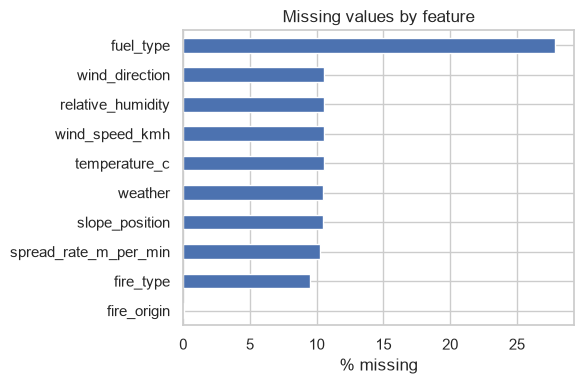

In [7]:
missing = X.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
ax = (missing * 100).plot.barh(figsize=(6, 4))
ax.set_xlabel("% missing"); ax.set_title("Missing values by feature"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig("figures/missing_values.png", dpi=150); plt.show()

### 2.5 Exploratory data analysis

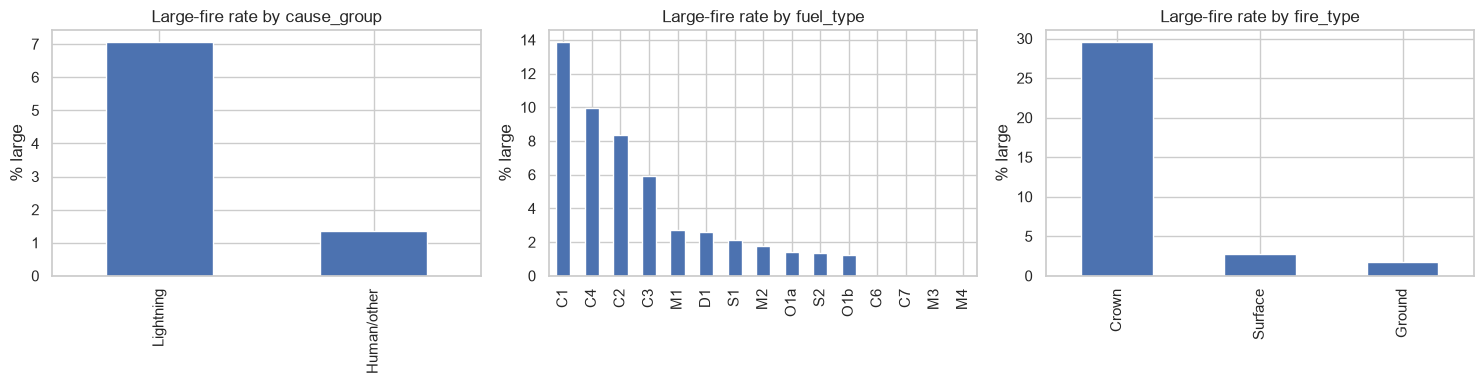

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
eda = X.assign(large=y)
for ax, col in zip(axes, ["cause_group", "fuel_type", "fire_type"]):
    rate = eda.groupby(col)["large"].mean().sort_values(ascending=False) * 100
    rate.plot.bar(ax=ax)
    ax.set_title(f"Large-fire rate by {col}"); ax.set_ylabel("% large"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("figures/large_rate_by_category.png", dpi=150); plt.show()

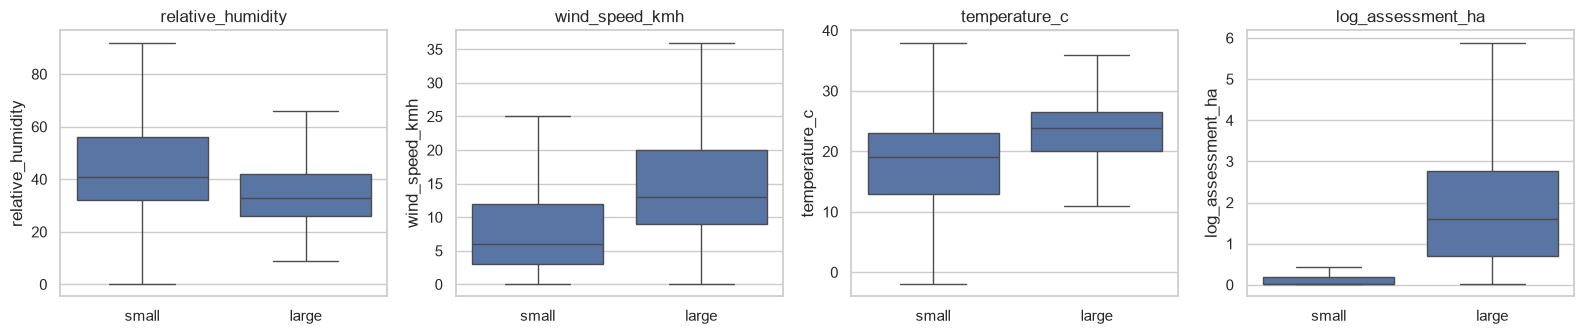

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["relative_humidity", "wind_speed_kmh", "temperature_c", "log_assessment_ha"]):
    sns.boxplot(x=y, y=X[col], ax=ax, showfliers=False)
    ax.set_xticks([0, 1], ["small", "large"]); ax.set_xlabel(""); ax.set_title(col)
plt.tight_layout(); plt.savefig("figures/numeric_by_class.png", dpi=150); plt.show()

### 2.6 Train/test split
Stratified 80/20 split, so both sets keep the 3.3% share of large fires. The test set is **not touched** until final evaluation.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"train: {X_train.shape}, large fires = {y_train.sum()}")
print(f"test:  {X_test.shape}, large fires = {y_test.sum()}")

train: (22262, 19), large fires = 746
test:  (5566, 19), large fires = 186


### 2.7 Shared preprocessing
Every model uses the same `ColumnTransformer`:
- **Numeric:** median imputation, then `StandardScaler` (scaling is skipped for tree models).
- **Categorical:** a `"missing"` category for missing values, then `OneHotEncoder`.

In [11]:
preprocessor = build_preprocessor(scale_numeric=True)
print(f"{preprocessor.fit_transform(X_train).shape[1]} columns after preprocessing")
preprocessor

84 columns after preprocessing


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## Step 3: ML models *(to do)*

| # | Model | Type | Scaling | Hyperparameters to tune |
|---|---|---|---|---|
| 0 | `DummyClassifier` | baseline | – | – |
| 0b | `LogisticRegression` on `log_assessment_ha` only | baseline | ✓ | – |
| 1 | `LogisticRegression` | linear | ✓ | `C`, `class_weight` |
| 2 | `LinearSVC` | linear | ✓ | `C`, `class_weight` |
| 3 | `RandomForestClassifier` | non-linear | ✗ | `n_estimators`, `max_depth`, `min_samples_leaf` |
| 4 | `GradientBoostingClassifier` | non-linear | ✗ | `n_estimators`, `learning_rate`, `max_depth` |
| 5 | `SVC` (RBF kernel) | non-linear | ✓ | `C`, `gamma` |
| 6 | `KNeighborsClassifier` | non-linear | ✓ | `n_neighbors`, `weights` |

Each model is `make_pipeline(build_preprocessor(scale_numeric=...), model)`, tuned with `GridSearchCV` on a `StratifiedKFold(5, shuffle=True, random_state=0)` and scored with `average_precision` (large fires are rare).

## Step 4: Validation *(to do)*
Compare cross-validation scores (train vs validation, to check for overfitting), then evaluate the best models **once** on the test set. Tune the decision threshold to the client's needs.

## Step 5: Visualization of results *(to do)*
Model comparison table, ROC and precision–recall curves, confusion matrix at the chosen threshold, and feature importances.